# **Lab 1: Feature Analysis of the Mobile Price Dataset**
**AIM**

To understand the structure, statistical properties, distributions, and relationships among features in the Mobile Price Classification dataset.

**ALGORITHM**

1. Import the required libraries.
2. Load the dataset.
3. Display the first and last records.
4. Inspect dimensions, data types, and missing values.
5. Generate descriptive statistics.
6. Separate numerical and categorical/binary features.
7. Plot the distribution of the target variable.
8. Plot important numerical features.
9. Construct a correlation matrix.
10. Identify features strongly related to price_range.


Dataset shape: (15, 11)


,Brand,Model,Price_USD,RAM_GB,Storage_GB,Battery_mAh,Screen_Size_Inch,Camera_MP,OS,Release_Year,price_range
0,Samsung,Galaxy S21,799,8,128,4000,6.20,64,Android,2021,2
1,Apple,iPhone 13,999,4,128,3240,6.10,12,iOS,2021,2
2,Xiaomi,Redmi Note 11,199,6,128,5000,6.43,50,Android,2022,0
3,Realme,Realme 9 Pro,299,8,128,5000,6.60,64,Android,2022,0
4,OnePlus,OnePlus 9,729,8,128,4500,6.55,48,Android,2021,2


,Brand,Model,Price_USD,RAM_GB,Storage_GB,Battery_mAh,Screen_Size_Inch,Camera_MP,OS,Release_Year,price_range
10,Tecno,Camon 18,219,6,128,5000,6.80,48,Android,2021,0
11,Apple,iPhone 12,899,4,64,2815,6.10,12,iOS,2020,2
12,Samsung,Galaxy A52,499,6,128,4500,6.50,64,Android,2021,1
13,Xiaomi,Poco X3 Pro,279,8,256,5160,6.67,48,Android,2021,0
14,Realme,Narzo 50,199,4,64,5000,6.60,50,Android,2022,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Brand             15 non-null     object 
 1   Model             15 non-null     object 
 2   Price_USD         15 non-null     int64  
 3   RAM_GB            15 non-null     int64  
 4   Storage_GB        15 non-null     int64  
 5   Battery_mAh       15 non-null     int64  
 6   Screen_Size_Inch  15 non-null     float64
 7   Camera_MP         15 non-null     int64  
 8   OS                15 non-null     object 
 9   Release_Year      15 non-null     int64  
 10  price_range       15 non-null     int64  
dtypes: float64(1), int64(7), object(3)
memory usage: 1.4+ KB

Missing values:
Brand               0
Model               0
Price_USD           0
RAM_GB              0
Storage_GB          0
Battery_mAh         0
Screen_Size_Inch    0
Camera_MP           0
OS       

,Price_USD,RAM_GB,Storage_GB,Battery_mAh,Screen_Size_Inch,Camera_MP,Release_Year,price_range
count,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000
mean,441.000000,6.266667,123.733333,4464.333333,6.472667,49.400000,2021.066667,0.733333
std,277.004384,1.667619,45.038819,706.391400,0.204955,24.523458,0.593617,0.883715
min,199.000000,4.000000,64.000000,2815.000000,6.100000,12.000000,2020.000000,0.000000
25%,234.000000,5.000000,128.000000,4100.000000,6.415000,48.000000,2021.000000,0.000000
50%,299.000000,6.000000,128.000000,4500.000000,6.510000,48.000000,2021.000000,0.000000
75%,614.000000,8.000000,128.000000,5000.000000,6.600000,64.000000,2021.000000,1.500000
max,999.000000,8.000000,256.000000,5160.000000,6.800000,108.000000,2022.000000,2.000000



Target distribution:
price_range
0    8
1    3
2    4
Name: count, dtype: int64


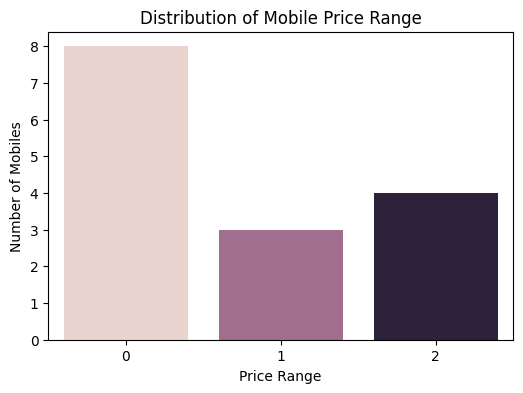

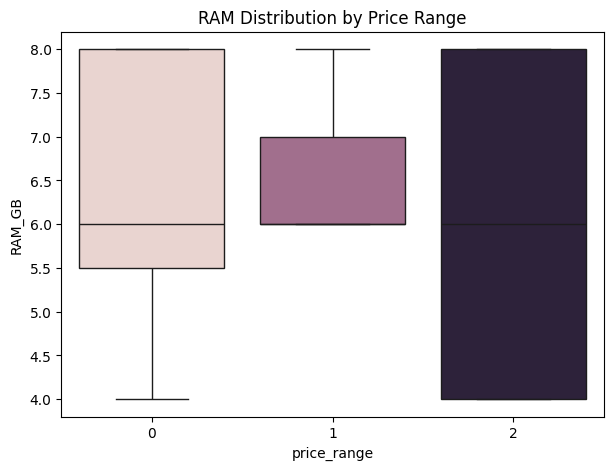

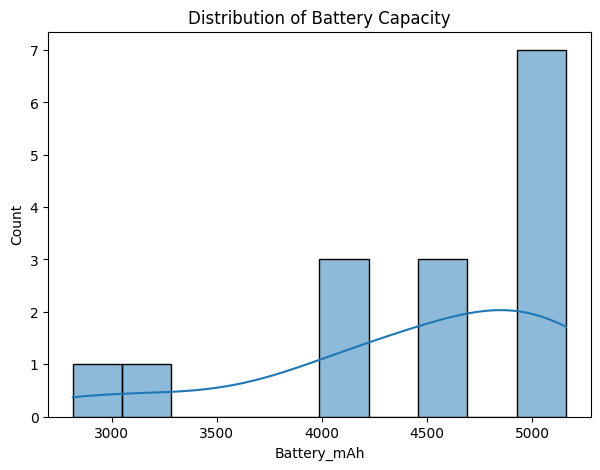

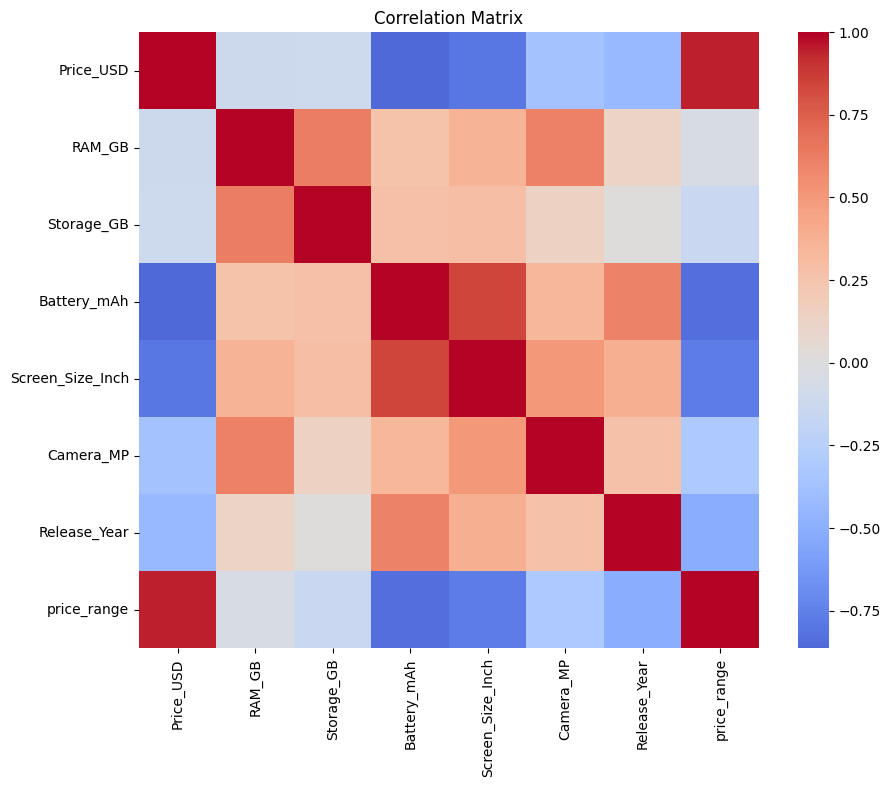


Correlation with price_range:
price_range         1.000000
Price_USD           0.947740
RAM_GB             -0.045238
Storage_GB         -0.145484
Camera_MP          -0.314432
Release_Year       -0.508335
Screen_Size_Inch   -0.772696
Battery_mAh        -0.835023
Name: price_range, dtype: float64


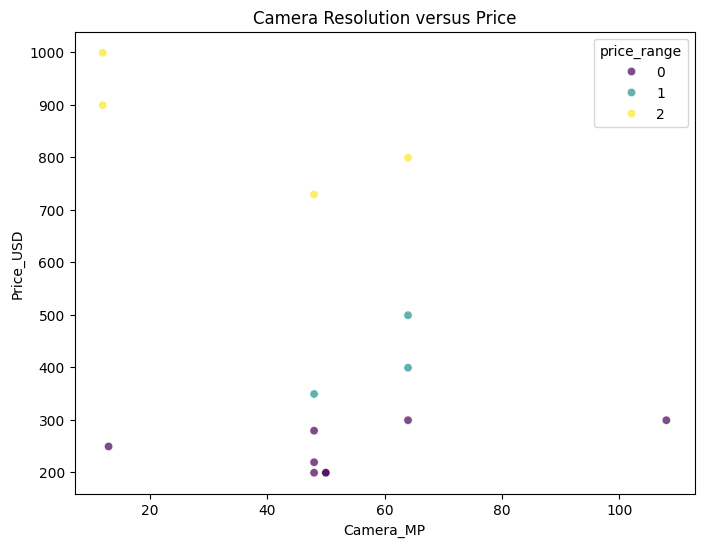

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("mobile_price_dataset.csv")

df["price_range"] = pd.cut(
    df["Price_USD"], bins=[0, 300, 600, float("inf")], labels=[0, 1, 2]
).astype(int)

print("Dataset shape:", df.shape)
display(df.head())
display(df.tail())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDescriptive statistics:")
display(df.describe())

print("\nTarget distribution:")
print(df["price_range"].value_counts().sort_index())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="price_range", hue="price_range", legend=False)
plt.title("Distribution of Mobile Price Range")
plt.xlabel("Price Range")
plt.ylabel("Number of Mobiles")
plt.show()

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="price_range", y="RAM_GB", hue="price_range", legend=False)
plt.title("RAM Distribution by Price Range")
plt.show()

plt.figure(figsize=(7, 5))
sns.histplot(data=df, x="Battery_mAh", kde=True, bins=10)
plt.title("Distribution of Battery Capacity")
plt.show()

corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

print("\nCorrelation with price_range:")
print(corr["price_range"].sort_values(ascending=False))

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="Camera_MP",
    y="Price_USD",
    hue="price_range",
    palette="viridis",
    alpha=0.7,
)
plt.title("Camera Resolution versus Price")
plt.show()

# **Lab 2: Data Preprocessing of the Mobile Price Dataset**
**AIM**

To identify and handle missing values and outliers in the Mobile Price dataset and produce a refined dataset for machine learning.

**ALGORITHM**

1. Load the dataset.
2. Check for duplicate records.
3. Check for missing values.
4. Identify numerical columns.
5. Detect outliers using the Interquartile Range method.
6. Visualize outliers using box plots.
7. Replace missing numerical values with the median.
8. Remove or cap extreme outliers.
9. Save the refined dataset.


Duplicate records: 0

Missing values:
Brand               0
Model               0
Price_USD           0
RAM_GB              0
Storage_GB          0
Battery_mAh         0
Screen_Size_Inch    0
Camera_MP           0
OS                  0
Release_Year        0
price_range         0
dtype: int64


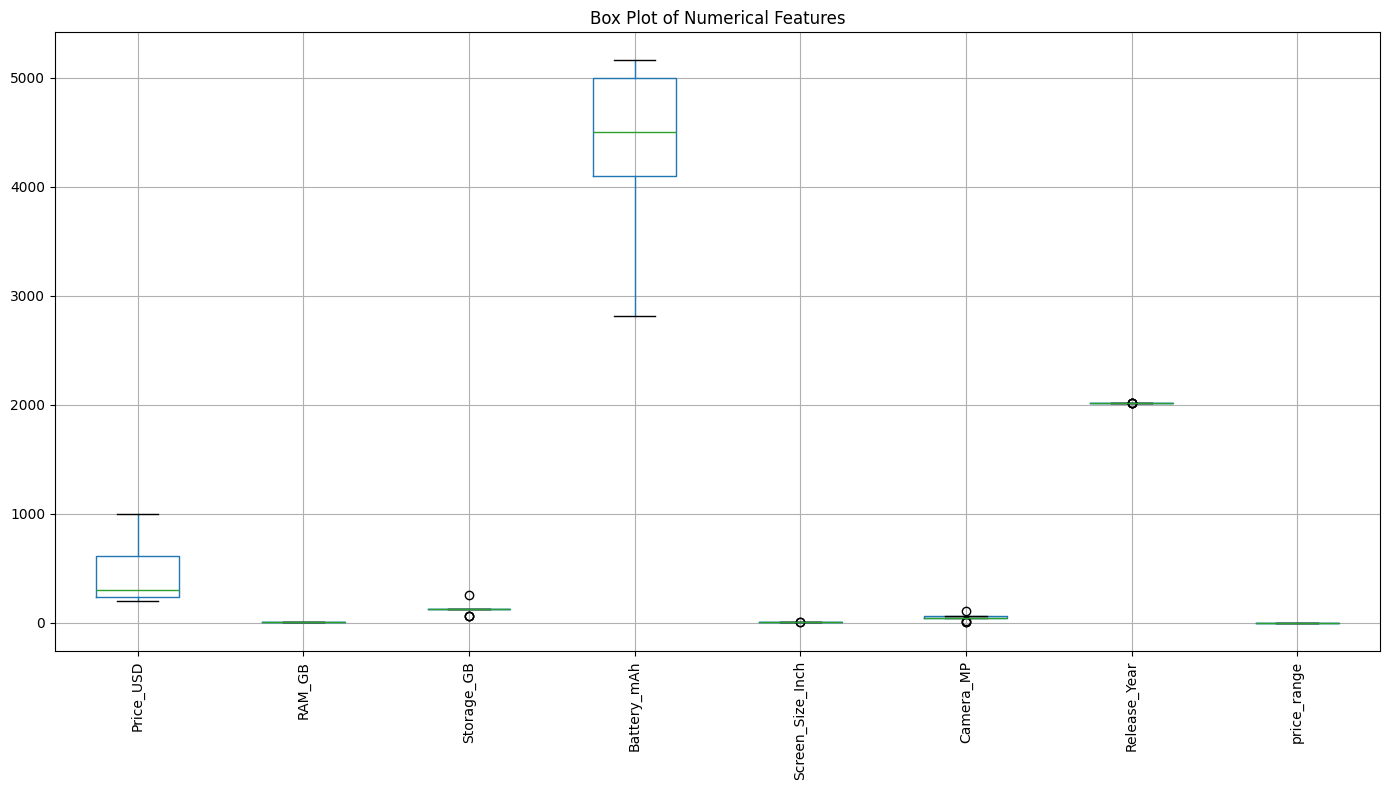

Outlier count by feature:
Release_Year        5
Storage_GB          4
Camera_MP           4
Screen_Size_Inch    2
Battery_mAh         0
RAM_GB              0
Price_USD           0
price_range         0
dtype: int64

Missing values after preprocessing:
0
Shape before preprocessing: (15, 11)
Shape after preprocessing: (15, 11)


In [ ]:
import numpy as np

print("Duplicate records:", df.duplicated().sum())
print("\nMissing values:")
print(df.isnull().sum())

numeric_columns = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(14, 8))
df[numeric_columns].boxplot(rot=90)
plt.title("Box Plot of Numerical Features")
plt.tight_layout()
plt.show()


def find_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return data[(data[column] < lower) | (data[column] > upper)]


outlier_summary = {column: len(find_outliers(df, column)) for column in numeric_columns}

print("Outlier count by feature:")
print(pd.Series(outlier_summary).sort_values(ascending=False))

df_clean = df.drop_duplicates().copy()

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

for column in numeric_columns:
    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df_clean[column] = df_clean[column].clip(lower, upper)

print("\nMissing values after preprocessing:")
print(df_clean.isnull().sum().sum())

print("Shape before preprocessing:", df.shape)
print("Shape after preprocessing:", df_clean.shape)

df_clean.to_csv("mobile_price_cleaned.csv", index=False)

# **Lab 3: Data Preprocessing of the Mobile Price Dataset**
**AIM**

To build machine learning classification models that predict the price range of a mobile phone using its technical features.

**ALGORITHM**

1. Load the refined dataset.
2. Separate independent features and target variable.
3. Split the data into training and testing sets.
4. Standardize the features where required.
5. Train multiple classification models.
6. Generate predictions.
7. Store the predictions and evaluation results.


In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

df = pd.read_csv("mobile_price_cleaned.csv")

X = pd.get_dummies(
    df.drop(columns=["price_range", "Price_USD", "Model"]),
    columns=["Brand", "OS"],
)
y = df["price_range"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ]),
}

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(name, "training completed")

new_mobile = pd.DataFrame([{
    "Brand": "Samsung",
    "RAM_GB": 8,
    "Storage_GB": 128,
    "Battery_mAh": 4500,
    "Screen_Size_Inch": 6.5,
    "Camera_MP": 64,
    "OS": "Android",
    "Release_Year": 2021,
}])

new_mobile = pd.get_dummies(new_mobile, columns=["Brand", "OS"]).reindex(
    columns=X.columns, fill_value=0
)

best_model = models["Random Forest"]
best_model.fit(X_train, y_train)

predicted_price_range = best_model.predict(new_mobile)
print("Predicted price range:", predicted_price_range[0])

Logistic Regression training completed
KNN training completed
Decision Tree training completed
Random Forest training completed
SVM training completed
Predicted price range: 1


# **Lab 4: Accuracy Calculation and Comparative Analysis of Mobile Models**
**AIM**

To evaluate and compare the performance of the machine learning models developed in Lab 3.

**ALGORITHM**

1. Use the test data and predictions generated in Lab 3.
2. Calculate:
*   Accuracy
*   Precision
*   Recall
*   F1-score
3. Display the results in a table.
4. Plot the accuracy of all models.
5. Select the model with the best performance.



,Model,Accuracy,Precision,Recall,F1 Score
1,KNN,0.666667,0.444444,0.666667,0.533333
4,SVM,0.666667,0.444444,0.666667,0.533333
0,Logistic Regression,0.333333,0.333333,0.333333,0.333333
2,Decision Tree,0.333333,0.666667,0.333333,0.444444
3,Random Forest,0.333333,0.666667,0.333333,0.444444


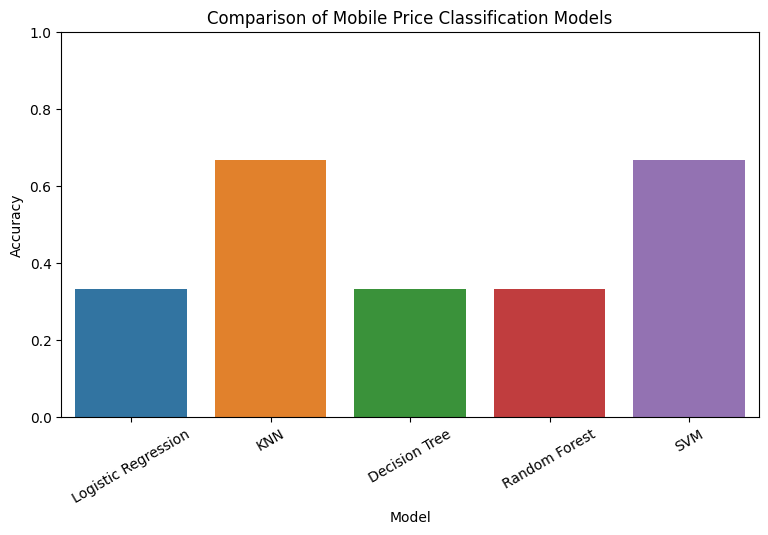

Best model: KNN


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results_df = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, prediction, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test, prediction, average="weighted", zero_division=0),
    }
    for name, prediction in predictions.items()
])

display(results_df.sort_values("Accuracy", ascending=False))

plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="Accuracy", hue="Model", legend=False)
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.title("Comparison of Mobile Price Classification Models")
plt.show()

best_model_name = results_df.loc[results_df["Accuracy"].idxmax(), "Model"]
print("Best model:", best_model_name)